In [1]:
import pathlib as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.integrate import cumulative_trapezoid

DATA_DIR = pl.Path("recorded-data")

paths = {
    "D25":   DATA_DIR / "Log_30.04.2026_09.03.30-25per.txt",
    "D50":   DATA_DIR / "Log_30.04.2026_09.06.16-50per.txt",
    "D75":   DATA_DIR / "Log_30.04.2026_09.09.11-75per.txt",
    "D100":  DATA_DIR / "Log_30.04.2026_09.14.01-100per.txt",
    "pmD25": DATA_DIR / "Log_30.04.2026_09.15.49-pm25per.txt",
}

FSAMPLE_HZ = 500  # from the `fsample=500Hz` header line


def load_log(path: pl.Path) -> pd.DataFrame:
    """Read a Serial.ICE log file (semicolon-separated, first line `fsample=...`)."""
    df = pd.read_csv(path, sep=";", skiprows=1, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    df["t/s"] = df["Time/ms"] / 1000.0
    return df


dfs = {key: load_log(paths[key]) for key in ("D25", "D50", "D75", "D100")}

division_factor = "25" # tangent through 25% to normalize it

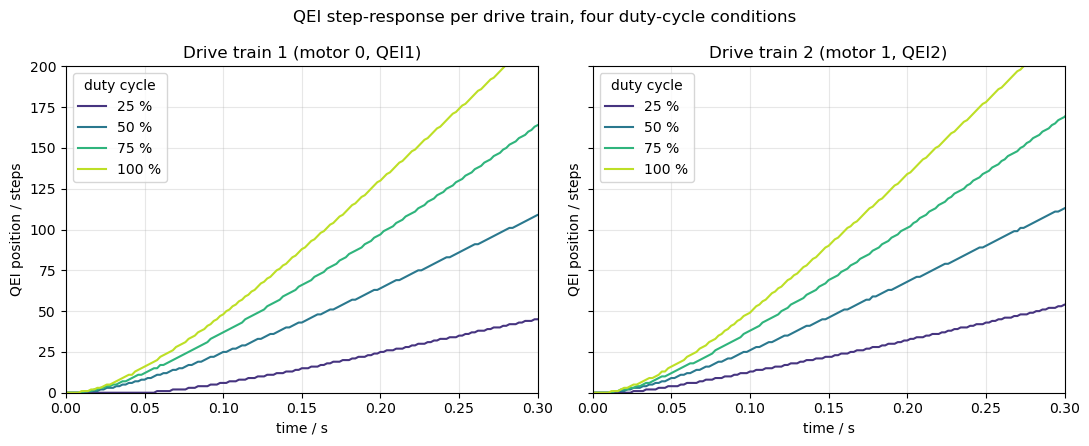

In [2]:
FIG_DIR = pl.Path("../01_RTP-Ausarbeitung/figure")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DRIVES = [("D25", "25 %"), ("D50", "50 %"), ("D75", "75 %"), ("D100", "100 %")]
DRIVE_COLORS = plt.cm.viridis([0.15, 0.4, 0.65, 0.9])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    axes[0].plot(dfs[key]["t/s"], dfs[key]["QEI1/steps"], label=label, color=color)
    axes[1].plot(dfs[key]["t/s"], dfs[key]["QEI2/steps"], label=label, color=color)
axes[0].set_title("Drive train 1 (motor 0, QEI1)")
axes[1].set_title("Drive train 2 (motor 1, QEI2)")
axes[0].set_ylim(0, 200)
axes[0].set_xlim(0, 0.3)
axes[1].set_xlim(0, 0.3)

for ax in axes:
    ax.set_xlabel("time / s")
    ax.set_ylabel("QEI position / steps")
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="upper left")
fig.suptitle("QEI step-response per drive train, four duty-cycle conditions")
fig.tight_layout()
fig.savefig(FIG_DIR / "drive-position-comparison.pdf", bbox_inches="tight")
#fig.savefig(FIG_DIR / "drive-position-comparison.png", dpi=200, bbox_inches="tight")
plt.show()



In [3]:
# # Ref cell 


# # sys2 IT1 identification (no dead time) with annotated plot
# t = data2[:, 0]
# u = data2[:, 1]  # input y(t)
# x = data2[:, 2]  # output x(t)

# # Plant proportional factor known from setup (input scaling K_p = 10).
# K_p_plant = 10.0

# # Step detection on input (0 -> 2).
# trigger_candidates = np.where((u[:-1] < 1.0) & (u[1:] >= 1.0))[0]
# trigger_idx = trigger_candidates[0] + 1 if len(trigger_candidates) > 0 else 0
# t_step = t[trigger_idx]

# # Input step height.
# u0 = np.mean(u[:max(1, trigger_idx)])
# u_inf = np.mean(u[trigger_idx:])
# du = u_inf - u0

# # Asymptotic tangent (lim t->inf) from last part of the measured response.
# tail_start = int(0.75 * len(t))
# if len(t) - tail_start < 5:
#     tail_start = max(trigger_idx, len(t) - 5)
# slope_inf, intercept_inf = np.polyfit(t[tail_start:], x[tail_start:], 1)

# # K_I from asymptotic slope: slope_inf = K_p_plant * K_I * delta_u
# # (the IT1 is preceded by a proportional element with K_p = 10).
# K_I = slope_inf / (du * K_p_plant) if abs(du) > 1e-12 else np.nan

# # Intersection of asymptotic tangent with time axis (x = 0).
# t_intersect = -intercept_inf / slope_inf if abs(slope_inf) > 1e-12 else np.nan

# # T_1 from tangent intersection relative to step origin (no dead time).
# T_1 = t_intersect - t_step if np.isfinite(t_intersect) else np.nan
# if np.isfinite(T_1):
#     T_1 = max(T_1, 1e-6)

# # IT1 model response to a step (no dead time) for visual comparison.
# x0 = np.mean(x[:max(1, trigger_idx)])
# tau = t - t_step
# tau_pos = np.maximum(tau, 0.0)
# if np.isfinite(T_1):
#     x_model = x0 + K_p_plant * K_I * du * (tau_pos - T_1 * (1.0 - np.exp(-tau_pos / T_1)))
# else:
#     x_model = x0 + K_p_plant * K_I * du * tau_pos

# # Pure-I reference: K_p_plant * K_I * integral(u(t) - u0) dt, plotted as dotted line.
# # Differs from the measured IT1 response by the first-order lag T_1.
# u_eff = u - u0
# x_int = x0 + K_p_plant * K_I * np.concatenate(([0.0], np.cumsum(0.5 * (u_eff[1:] + u_eff[:-1]) * np.diff(t))))

# # Asymptotic tangent line over plotting range.
# tangent_inf = slope_inf * t + intercept_inf

# # Plot: left input, right output identification.
# fig, (ax_in, ax_out) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 2]})

# ax_in.plot(t, u, color='tab:orange', label='y(t) input', linewidth=2)
# ax_in.axvline(t_step, color='black', linestyle='--', label='step origin')
# ax_in.axhline(u_inf, color='tab:orange', linestyle=':', label=r'$u_\infty$')
# ax_in.set_title('sys2 input signal')
# ax_in.set_xlabel('$t/s$')
# ax_in.set_ylabel('$y(t)$')
# ax_in.grid()
# ax_in.legend(loc='best')

# ax_out.plot(t, x, label='x(t) measured', linewidth=2)
# ax_out.plot(t, x_model, ':', label='IT1 model')
# ax_out.plot(t, x_int, linestyle=(0, (1, 1)), color='tab:red', label=r'$K_p \cdot K_I \int u\,dt$ (pure I)')
# ax_out.plot(t, tangent_inf, '--', label=r'$\lim_{t\to\infty}$ tangent')

# ax_out.axvline(t_step, color='black', linestyle='--', label='step origin')
# if np.isfinite(t_intersect):
#     ax_out.axvline(t_intersect, color='tab:green', linestyle='--', label='t-axis intersection')
#     ax_out.scatter([t_intersect], [0.0], color='tab:green', zorder=5)

# # Slope triangle on the asymptotic tangent: delta t = 1 s.
# triangle_shift = 1.0
# triangle_base = t_step + 0.5 + triangle_shift
# t_tri0 = max(triangle_base, t[0])
# t_tri1 = min(t_tri0 + 1.0, t[-1])
# if t_tri1 - t_tri0 < 1e-9:
#     t_tri0 = max(t[-1] - 1.0, t[0])
#     t_tri1 = t[-1]
# x_tri0 = slope_inf * t_tri0 + intercept_inf
# x_tri1 = slope_inf * t_tri1 + intercept_inf

# ax_out.plot([t_tri0, t_tri1], [x_tri0, x_tri0], color='tab:blue', linewidth=2)
# ax_out.plot([t_tri1, t_tri1], [x_tri0, x_tri1], color='tab:blue', linewidth=2)
# ax_out.text((t_tri0 + t_tri1) / 2.0, x_tri0, '1 s', color='tab:blue', ha='center', va='bottom')
# ax_out.text(t_tri1, (x_tri0 + x_tri1) / 2.0, r'$K_p \cdot K_I \cdot \Delta u$', color='tab:blue', ha='left', va='center')

# # Keep readable scale from measured output.
# y_min = np.min(x)
# y_max = np.max(x)
# y_pad = 0.1 * (y_max - y_min) if y_max > y_min else 1.0
# ax_out.set_xlim(t[0], t[-1])
# ax_out.set_ylim(y_min - y_pad, y_max + y_pad)

# ax_out.set_title('sys2: IT1 identification with marked parameters')
# ax_out.set_xlabel('$t/s$')
# ax_out.set_ylabel('$x(t)$')
# ax_out.grid()
# ax_out.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)

# # Annotation box with identified parameters, placed below the legend (outside the plot, on the right).
# annot_text = (
#     f'$K_p$ = {K_p_plant:.4f} (given)\n'
#     f'$K_I$ = {K_I:.4f} 1/s\n'
#     f'$T_1$ = {T_1:.4f} s\n'
#     f'slope$_\\infty$ = {slope_inf:.4f}\n'
#     f'$\\Delta u$ = {du:.4f}'
# )
# ax_out.text(
#     1.02, 0.0, annot_text,
#     transform=ax_out.transAxes, va='bottom', ha='left',
#     bbox=dict(boxstyle='round', facecolor='white', alpha=0.85)
# )

# plt.tight_layout()
# plt.subplots_adjust(right=0.78)
# plt.show()
# fig.savefig('figure_out/sys2_it1_identification.' + fileformat, dpi=resolution, bbox_inches='tight')

# print('Estimated sys2 IT1 parameters (with K_p = 10 given):')
# print(f'K_p (given) = {K_p_plant:.6f}')
# print(f'K_I = {K_I:.6f} 1/s')
# print(f'T_1 = {T_1:.6f} s')
# print('Transfer function (IT1, including K_p):')
# print(f'G(s) = ({K_p_plant:.6f} * {K_I:.6f}) / (s * ({T_1:.6f} s + 1))')


## IT$_1$ system identification of both drive trains

Each drive (left = motor 0 / QEI1, right = motor 1 / QEI2) maps the **duty cycle** $\delta\,/\,\%$ to the **travelled distance** $x\,/\,\mathrm{cm}$ and behaves as an IT$_1$ element:

$$G(s) = \frac{K_I}{s\,(T_1 s + 1)}, \qquad h(t) = K_I\left(t - T_1\bigl(1 - e^{-t/T_1}\bigr)\right).$$

**Path to the solution (per duty cycle, per motor):**

1. Convert the QEI step counts to a distance with $x = \dfrac{\text{steps}}{360^\circ}\, d_R\, \pi$ and $d_R = \SI{5.6}{cm}$.
2. Fit the **asymptotic tangent** $x_\infty(t) = a\,t + b$ to the settled (linear) tail of the step response.
3. The tangent slope equals $K_I\,\delta$, so the **normalised integral gain** is $K_I = a/\delta$ in $\mathrm{cm/(s\cdot\%)}$.
4. The tangent crosses the time axis at $t = t_\text{step} + T_1$, giving the **time constant** $T_1 = -b/a - t_\text{step}$.

The two cells below compute $K_I$ and $T_1$ for all four duty cycles, **average each motor over its four speeds**, and plot the asymptotic tangents. The reference cell above (`sys2`) is the template for this procedure.


In [4]:
# ---------------------------------------------------------------------------
# IT1 identification of both drive trains (no dead time)
# ---------------------------------------------------------------------------
# QEI step counts -> travelled distance via eq:weg_aus_winkel:
#     x = steps / 360 * d_R * pi          with the wheel diameter d_R = 5.6 cm.
# Each drive (input = duty cycle delta / %, output = position x / cm) behaves
# as an IT1 system:   G(s) = K_I / (s (T_1 s + 1)).
# Its step response is a ramp whose asymptotic tangent has slope  K_I * delta
# and crosses the time axis at  t_step + T_1.  Therefore, per duty cycle:
#     K_I = slope_inf / delta     (normalised per duty-cycle %, cf. division_factor)
#     T_1 = t_intersect - t_step
# K_I and T_1 are finally averaged over the four duty cycles, for each motor.

D_R = 5.6                       # wheel diameter / cm  (eq:weg_aus_winkel)
STEP2CM = D_R * np.pi / 360.0   # one QEI step -> travelled distance / cm

DUTY = {"D25": 25.0, "D50": 50.0, "D75": 75.0, "D100": 100.0}
TAIL_FRAC = 0.60                # fit the tangent on the settled (linear) tail
MOTORS = [("QEI1/steps", "Left motor (motor 0, QEI1)"),
          ("QEI2/steps", "Right motor (motor 1, QEI2)")]


def identify_it1(t, u, steps, duty, tail_frac=TAIL_FRAC):
    """IT1 identification on a QEI position step response (no dead time).

    The step origin is the moment the duty cycle is applied: a 0 -> duty edge
    in the input signal `u` when present (D25), otherwise t = 0 because the
    duty is already active at the start of the recording (D50/D75/D100).  This
    is the same input-step detection as the reference `sys2` cell and is more
    robust than triggering on the first QEI count (which can fire on encoder
    jitter before the actual step).  The asymptotic tangent is a straight-line
    fit to the settled (linear) tail of x(t).
    """
    x = steps * STEP2CM                                 # position / cm
    trig = np.where((u[:-1] < 1.0) & (u[1:] >= 1.0))[0]
    trigger_idx = int(trig[0]) + 1 if len(trig) else 0
    t_step = t[trigger_idx]

    tail_start = int(tail_frac * len(t))
    slope_inf, intercept_inf = np.polyfit(t[tail_start:], x[tail_start:], 1)
    t_intersect = -intercept_inf / slope_inf            # tangent crosses x = 0

    K_I = slope_inf / duty                              # cm / (s * %)
    T_1 = t_intersect - t_step
    return dict(duty=duty, t_step=t_step, slope_inf=slope_inf,
                intercept_inf=intercept_inf, t_intersect=t_intersect,
                K_I=K_I, T_1=T_1, trigger_idx=trigger_idx)


ident = {}            # ident[motor_name][drive_key] -> result dict
summary_rows = []
for col, name in MOTORS:
    ident[name] = {}
    for key, label in DRIVES:
        df = dfs[key]
        r = identify_it1(df["t/s"].values, df["Mot0/%"].values,
                         df[col].values, DUTY[key])
        ident[name][key] = r
        summary_rows.append({
            "motor": name, "drive": label, "delta/%": DUTY[key],
            "slope_inf/cm/s": r["slope_inf"],
            "K_I/cm/(s*%)": r["K_I"], "T_1/ms": r["T_1"] * 1e3,
        })

summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False,
                        float_format=lambda v: f"{v:9.4f}"))
print()

averages = {}
for col, name in MOTORS:
    sub = summary[summary["motor"] == name]
    K_I_avg = sub["K_I/cm/(s*%)"].mean()
    T_1_avg = sub["T_1/ms"].mean()
    averages[name] = (K_I_avg, T_1_avg)
    print(f"{name}")
    print(f"    K_I_avg = {K_I_avg:.4f} cm/(s*%)   "
          f"(sd {sub['K_I/cm/(s*%)'].std():.4f})")
    print(f"    T_1_avg = {T_1_avg:.2f} ms = {T_1_avg / 1e3:.4f} s   "
          f"(sd {sub['T_1/ms'].std():.2f} ms)")
    print(f"    G(s) = {K_I_avg:.3f} / (s ({T_1_avg / 1e3:.4f} s + 1))")
    print()


                      motor drive   delta/%  slope_inf/cm/s  K_I/cm/(s*%)    T_1/ms
 Left motor (motor 0, QEI1)  25 %   25.0000         10.2724        0.4109   59.1133
 Left motor (motor 0, QEI1)  50 %   50.0000         21.8954        0.4379   50.9466
 Left motor (motor 0, QEI1)  75 %   75.0000         33.6763        0.4490   63.0547
 Left motor (motor 0, QEI1) 100 %  100.0000         44.9191        0.4492   55.3605
Right motor (motor 1, QEI2)  25 %   25.0000         10.5382        0.4215   40.4807
Right motor (motor 1, QEI2)  50 %   50.0000         22.4389        0.4488   49.6909
Right motor (motor 1, QEI2)  75 %   75.0000         34.2385        0.4565   57.9448
Right motor (motor 1, QEI2) 100 %  100.0000         45.8991        0.4590   60.7124

Left motor (motor 0, QEI1)
    K_I_avg = 0.4368 cm/(s*%)   (sd 0.0180)
    T_1_avg = 57.12 ms = 0.0571 s   (sd 5.18 ms)
    G(s) = 0.437 / (s (0.0571 s + 1))

Right motor (motor 1, QEI2)
    K_I_avg = 0.4465 cm/(s*%)   (sd 0.0172)
    T_1_avg 

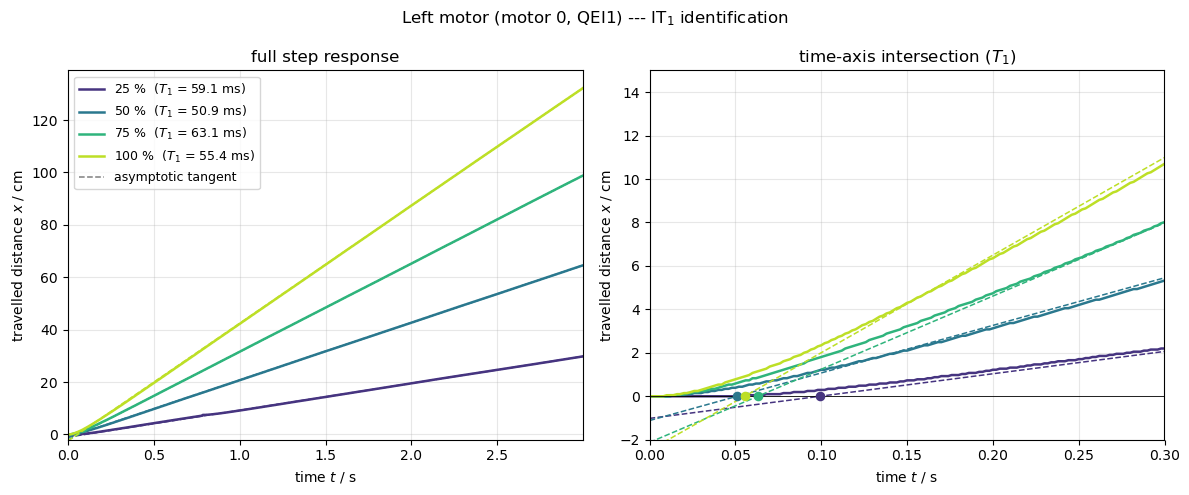

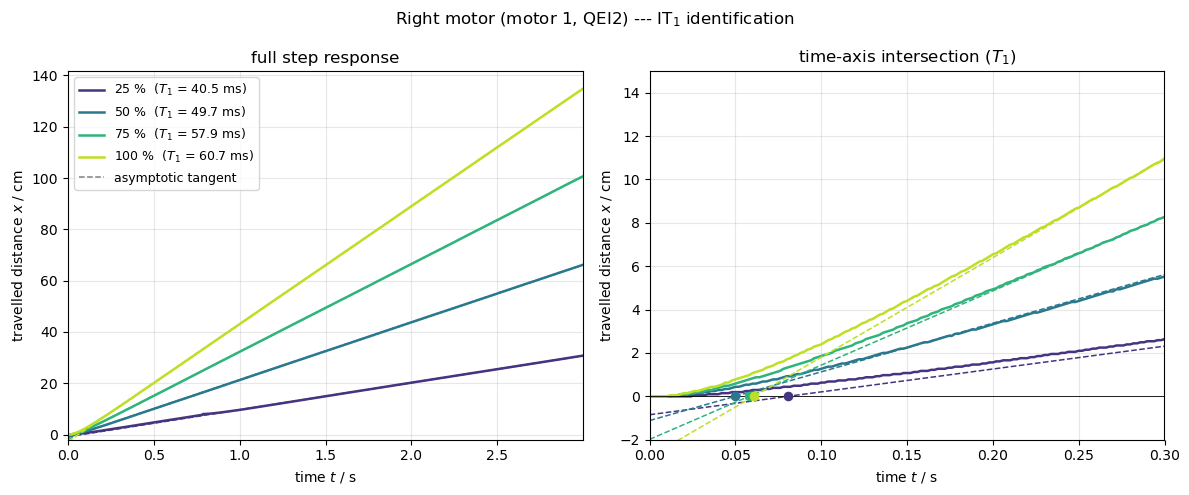

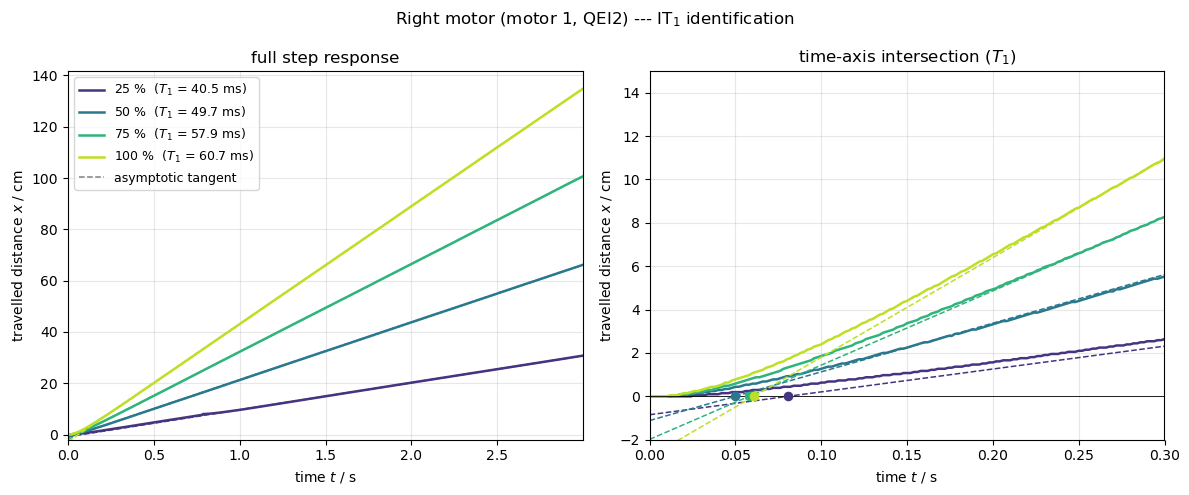

In [5]:
# ---------------------------------------------------------------------------
# Asymptotic-tangent plots per motor (all four duty cycles in one figure)
# ---------------------------------------------------------------------------
# Left panel : full step response with the fitted asymptotic tangents.
# Right panel: zoom on the first 0.3 s, where each tangent crosses the time
#              axis at t_step + T_1 (markers).
from matplotlib.lines import Line2D


def plot_tangents(col, name, fname):
    fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(12, 5))
    K_I_list, T_1_list = [], []
    for (key, label), color in zip(DRIVES, DRIVE_COLORS):
        df = dfs[key]
        t = df["t/s"].values
        x = df[col].values * STEP2CM
        r = ident[name][key]
        K_I_list.append(r["K_I"])
        T_1_list.append(r["T_1"])
        tangent = r["slope_inf"] * t + r["intercept_inf"]
        leg = f"{label}  ($T_1$ = {r['T_1'] * 1e3:.1f} ms)"
        for ax in (ax_full, ax_zoom):
            ax.plot(t, x, color=color, lw=1.8, label=leg)
            ax.plot(t, tangent, color=color, ls="--", lw=1.1)
        ax_zoom.scatter([r["t_intersect"]], [0.0], color=color, s=35, zorder=5)

    K_I_avg = float(np.mean(K_I_list))
    T_1_avg = float(np.mean(T_1_list))

    ax_full.set_xlim(0, t.max())
    ax_full.set_ylim(bottom=-2)
    ax_full.set_title("full step response")
    ax_zoom.set_xlim(0, 0.3)
    ax_zoom.set_ylim(-2, 15)
    ax_zoom.axhline(0, color="k", lw=0.6)
    ax_zoom.set_title("time-axis intersection ($T_1$)")

    # extra legend entry explaining the dashed lines
    h, l = ax_full.get_legend_handles_labels()
    h.append(Line2D([0], [0], color="grey", ls="--", lw=1.1))
    l.append("asymptotic tangent")
    for ax in (ax_full, ax_zoom):
        ax.set_xlabel("time $t$ / s")
        ax.set_ylabel("travelled distance $x$ / cm")
        ax.grid(True, alpha=0.3)
    ax_full.legend(h, l, loc="upper left", fontsize=9)

    fig.suptitle(f"{name} --- IT$_1$ identification")
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()
    return fig


plot_tangents("QEI1/steps", "Left motor (motor 0, QEI1)",  "it1-tangents-left.pdf")
plot_tangents("QEI2/steps", "Right motor (motor 1, QEI2)", "it1-tangents-right.pdf")


## Travelled distance from the QEI step counts

The raw recordings store the encoder position in **QEI steps** (columns `QEI1/steps`,
`QEI2/steps`). For the report (task (d)) these are converted into the **travelled
distance** $x$ of each wheel with eq:weg_aus_winkel,

$$x_i = \frac{\text{steps}}{360^\circ}\, d_R\, \pi, \qquad d_R = \SI{5.6}{cm},$$

i.e. one full revolution ($360^\circ$) advances the wheel by its circumference
$d_R\,\pi$. The cell below applies this conversion to both drive trains for all four
duty cycles and plots the travelled distance over time. The figure is saved as
`figure/distance-traveled.pdf` for inclusion in the report.


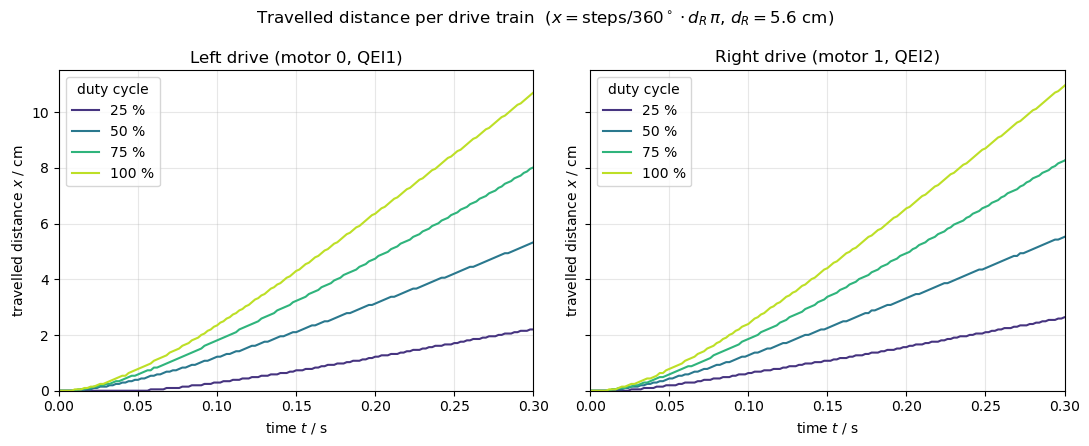

In [6]:
# ---------------------------------------------------------------------------
# QEI step counts -> travelled distance (eq:weg_aus_winkel) and plot
# ---------------------------------------------------------------------------
#     x = steps / 360 * d_R * pi      with wheel diameter d_R = 5.6 cm
# One revolution (360 deg) advances the wheel by its circumference d_R * pi.
D_R = 5.6                       # wheel diameter / cm  (eq:weg_aus_winkel)
STEP2CM = D_R * np.pi / 360.0   # one QEI step -> travelled distance / cm

# Add a travelled-distance column per motor to every duty-cycle DataFrame.
for key, _ in DRIVES:
    dfs[key]["x_left/cm"] = dfs[key]["QEI1/steps"] * STEP2CM
    dfs[key]["x_right/cm"] = dfs[key]["QEI2/steps"] * STEP2CM

T_VIEW = 0.3   # plotted time window / s

# Plot: travelled distance over time, left and right drive train.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    axes[0].plot(dfs[key]["t/s"], dfs[key]["x_left/cm"], label=label, color=color)
    axes[1].plot(dfs[key]["t/s"], dfs[key]["x_right/cm"], label=label, color=color)
axes[0].set_title("Left drive (motor 0, QEI1)")
axes[1].set_title("Right drive (motor 1, QEI2)")

# y-limit matched to the plotted window (autoscale would use the full record).
x_view_max = max(
    dfs[key].loc[dfs[key]["t/s"] <= T_VIEW, ["x_left/cm", "x_right/cm"]].to_numpy().max()
    for key, _ in DRIVES
)
for ax in axes:
    ax.set_xlim(0, T_VIEW)
    ax.set_ylim(0, 1.05 * x_view_max)
    ax.set_xlabel("time $t$ / s")
    ax.set_ylabel("travelled distance $x$ / cm")
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="upper left")
fig.suptitle(r"Travelled distance per drive train  ($x = \mathrm{steps}/360^\circ \cdot d_R\,\pi$, $d_R = 5.6$ cm)")
fig.tight_layout()
fig.savefig(FIG_DIR / "distance-traveled.pdf", bbox_inches="tight")
plt.show()


## IT$_1$ identification on the travelled distance $x(t)$ (results marked)

Now that the QEI step counts have been converted to a travelled distance via
eq:weg_aus_winkel (columns `x_left/cm` and `x_right/cm`), the IT$_1$
identification is repeated **directly on $x(t)$** -- one analysis per duty
cycle, then averaged over the four duty cycles per motor. The procedure is
identical to the analysis above (numerical results are the same, the inputs
are just labelled in cm rather than steps):

1. Detect the step origin from the input duty-cycle signal (0&nbsp;%&nbsp;$\to\delta$ edge).
2. Fit the asymptotic tangent $x_\infty(t) = a\,t + b$ to the settled tail.
3. $K_I = a / \delta$  (slope normalised per duty-cycle %, in cm/(s$\cdot$%)).
4. $T_1 = -b/a - t_\text{step}$ (tangent's time-axis intersection minus the step origin).

The figure produced below shows, **per motor**, the measured travelled
distance $x(t)$ for all four duty cycles, the fitted asymptotic tangents, the
time-axis intersections that yield $T_1$, and an annotation box giving the
averaged parameters $\overline{K_I}$, $\overline{T_1}$ together with the
resulting transfer function $G(s)$.

                      motor drive   delta/%  slope_inf/cm/s  K_I/cm/(s*%)    T_1/ms
 Left motor (motor 0, QEI1)  25 %   25.0000         10.2724        0.4109   59.1133
 Left motor (motor 0, QEI1)  50 %   50.0000         21.8954        0.4379   50.9466
 Left motor (motor 0, QEI1)  75 %   75.0000         33.6763        0.4490   63.0547
 Left motor (motor 0, QEI1) 100 %  100.0000         44.9191        0.4492   55.3605
Right motor (motor 1, QEI2)  25 %   25.0000         10.5382        0.4215   40.4807
Right motor (motor 1, QEI2)  50 %   50.0000         22.4389        0.4488   49.6909
Right motor (motor 1, QEI2)  75 %   75.0000         34.2385        0.4565   57.9448
Right motor (motor 1, QEI2) 100 %  100.0000         45.8991        0.4590   60.7124

Left motor (motor 0, QEI1)
    K_I_avg = 0.4368 cm/(s*%)   (sd 0.0180)
    T_1_avg = 57.12 ms = 0.0571 s   (sd 5.18 ms)
    G(s) = 0.437 / (s (0.0571 s + 1))

Right motor (motor 1, QEI2)
    K_I_avg = 0.4465 cm/(s*%)   (sd 0.0172)
    T_1_avg 

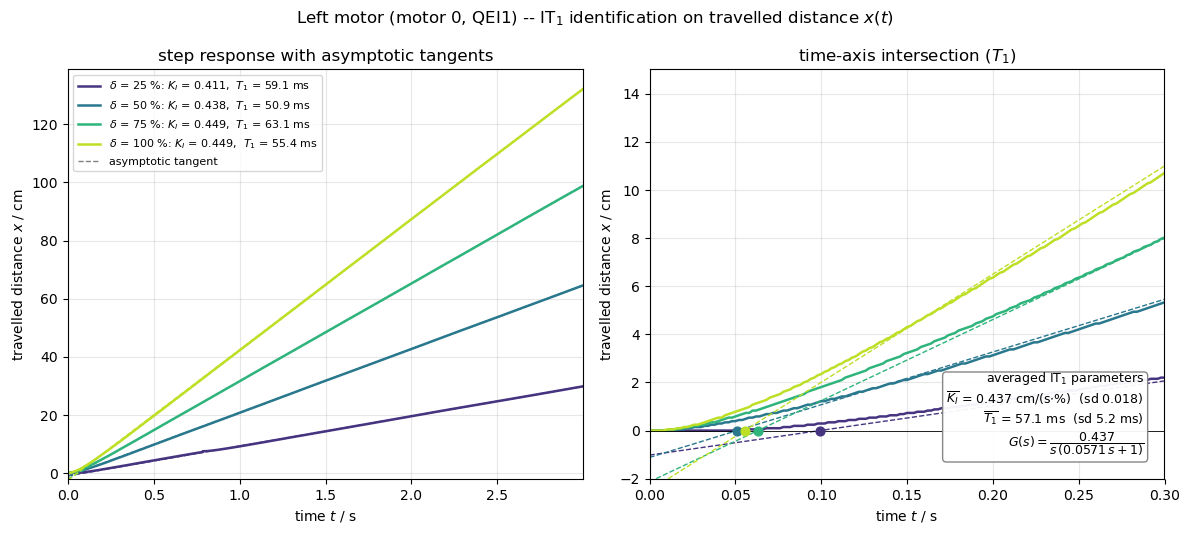

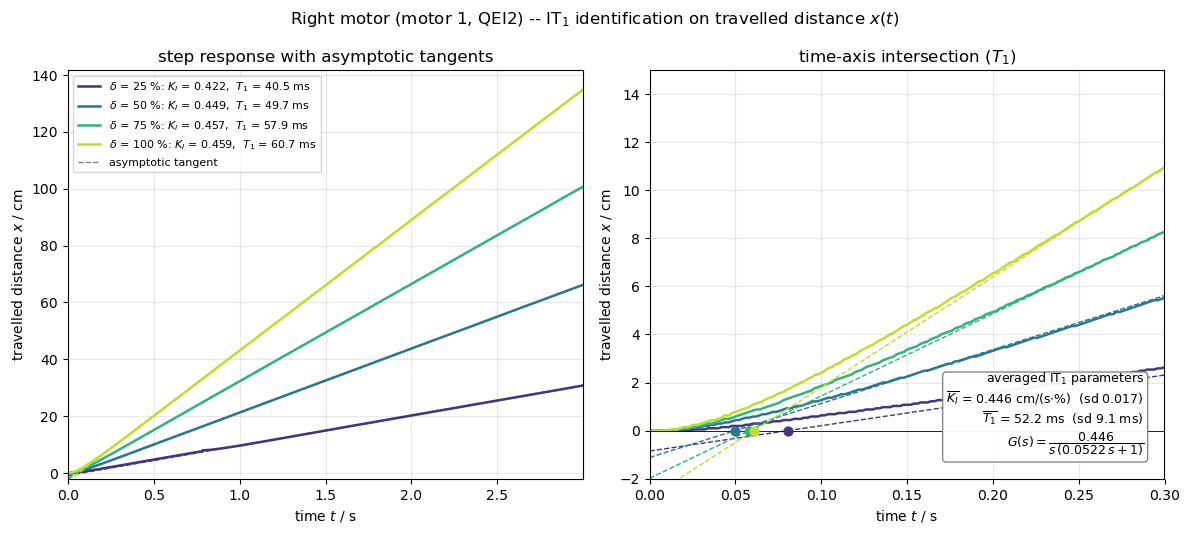

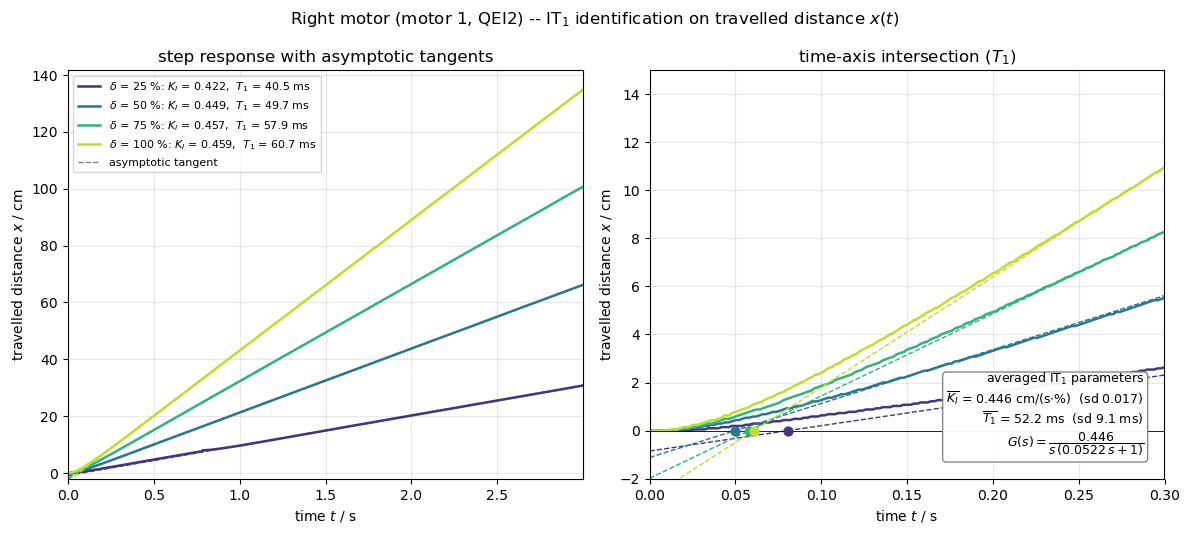

In [7]:
# ---------------------------------------------------------------------------
# IT1 identification on the travelled distance x(t) -- results marked on plot
# ---------------------------------------------------------------------------
# Same procedure as identify_it1() above, but applied directly to the
# travelled-distance columns x_left/cm and x_right/cm created in the previous
# cell.  Numerical results are identical to the earlier QEI-position analysis;
# the figures here additionally annotate K_I, T_1 per duty cycle and the
# averaged parameters on the plot itself, so they are self-contained for the
# report.
from matplotlib.lines import Line2D


def identify_it1_x(t, u, x, duty, tail_frac=TAIL_FRAC):
    """IT1 identification on the travelled distance x(t) [cm], no dead time."""
    trig = np.where((u[:-1] < 1.0) & (u[1:] >= 1.0))[0]
    trigger_idx = int(trig[0]) + 1 if len(trig) else 0
    t_step = t[trigger_idx]
    tail_start = int(tail_frac * len(t))
    slope_inf, intercept_inf = np.polyfit(t[tail_start:], x[tail_start:], 1)
    t_intersect = -intercept_inf / slope_inf
    K_I = slope_inf / duty            # cm / (s * %)
    T_1 = t_intersect - t_step        # s
    return dict(duty=duty, t_step=t_step, slope_inf=slope_inf,
                intercept_inf=intercept_inf, t_intersect=t_intersect,
                K_I=K_I, T_1=T_1, trigger_idx=trigger_idx)


DRIVE_X = [("x_left/cm",  "Left motor (motor 0, QEI1)"),
           ("x_right/cm", "Right motor (motor 1, QEI2)")]

ident_x, rows_x = {}, []
for col, name in DRIVE_X:
    ident_x[name] = {}
    for key, label in DRIVES:
        df = dfs[key]
        r = identify_it1_x(df["t/s"].values, df["Mot0/%"].values,
                           df[col].values, DUTY[key])
        ident_x[name][key] = r
        rows_x.append({"motor": name, "drive": label, "delta/%": DUTY[key],
                       "slope_inf/cm/s": r["slope_inf"],
                       "K_I/cm/(s*%)": r["K_I"], "T_1/ms": r["T_1"] * 1e3})

summary_x = pd.DataFrame(rows_x)
print(summary_x.to_string(index=False, float_format=lambda v: f"{v:9.4f}"))
print()

for col, name in DRIVE_X:
    sub = summary_x[summary_x["motor"] == name]
    K_I_avg = sub["K_I/cm/(s*%)"].mean()
    T_1_avg = sub["T_1/ms"].mean()
    print(f"{name}")
    print(f"    K_I_avg = {K_I_avg:.4f} cm/(s*%)   "
          f"(sd {sub['K_I/cm/(s*%)'].std():.4f})")
    print(f"    T_1_avg = {T_1_avg:.2f} ms = {T_1_avg / 1e3:.4f} s   "
          f"(sd {sub['T_1/ms'].std():.2f} ms)")
    print(f"    G(s) = {K_I_avg:.3f} / (s ({T_1_avg / 1e3:.4f} s + 1))")
    print()


def plot_it1_x_marked(col, name, fname):
    fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(12, 5.4))
    K_I_list, T_1_list, t_max_used = [], [], 0.0
    for (key, label), color in zip(DRIVES, DRIVE_COLORS):
        df = dfs[key]
        t = df["t/s"].values
        x = df[col].values
        r = ident_x[name][key]
        K_I_list.append(r["K_I"])
        T_1_list.append(r["T_1"])
        tangent = r["slope_inf"] * t + r["intercept_inf"]
        leg = (f"$\\delta$ = {label}: "
               f"$K_I$ = {r['K_I']:.3f},  $T_1$ = {r['T_1']*1e3:.1f} ms")
        for ax in (ax_full, ax_zoom):
            ax.plot(t, x, color=color, lw=1.8, label=leg)
            ax.plot(t, tangent, color=color, ls="--", lw=1.0)
        ax_zoom.scatter([r["t_intersect"]], [0.0], color=color, s=40, zorder=5)
        t_max_used = max(t_max_used, t.max())

    K_I_avg = float(np.mean(K_I_list))
    T_1_avg = float(np.mean(T_1_list))
    K_I_sd  = float(np.std(K_I_list, ddof=1))
    T_1_sd  = float(np.std(T_1_list, ddof=1))

    ax_full.set_xlim(0, t_max_used)
    ax_full.set_ylim(bottom=-2)
    ax_full.set_title("step response with asymptotic tangents")
    ax_zoom.set_xlim(0, 0.3)
    ax_zoom.set_ylim(-2, 15)
    ax_zoom.axhline(0, color="k", lw=0.6)
    ax_zoom.set_title("time-axis intersection ($T_1$)")

    annot = (
        "averaged IT$_1$ parameters\n"
        f"$\\overline{{K_I}}$ = {K_I_avg:.3f} cm/(s$\\cdot$%)  (sd {K_I_sd:.3f})\n"
        f"$\\overline{{T_1}}$ = {T_1_avg*1e3:.1f} ms  (sd {T_1_sd*1e3:.1f} ms)\n"
        f"$G(s) = \\dfrac{{{K_I_avg:.3f}}}{{s\\,({T_1_avg:.4f}\\,s + 1)}}$"
    )
    ax_zoom.text(0.96, 0.05, annot, transform=ax_zoom.transAxes,
                 va="bottom", ha="right", fontsize=9,
                 bbox=dict(boxstyle="round", facecolor="white",
                           edgecolor="grey", alpha=0.95))

    h, l = ax_full.get_legend_handles_labels()
    h.append(Line2D([0], [0], color="grey", ls="--", lw=1.0))
    l.append("asymptotic tangent")
    for ax in (ax_full, ax_zoom):
        ax.set_xlabel("time $t$ / s")
        ax.set_ylabel("travelled distance $x$ / cm")
        ax.grid(True, alpha=0.3)
    ax_full.legend(h, l, loc="upper left", fontsize=8)

    fig.suptitle(f"{name} -- IT$_1$ identification on travelled distance $x(t)$")
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()
    return fig


plot_it1_x_marked("x_left/cm",  "Left motor (motor 0, QEI1)",
                  "it1-distance-left.pdf")
plot_it1_x_marked("x_right/cm", "Right motor (motor 1, QEI2)",
                  "it1-distance-right.pdf")
